# 🔎 Reranker Evaluation Analysis

This notebook analyses how different combinations of `retriever_k` and `reranker_n` affect retrieval quality in our RAG system. Our primary goal is to measure whether the reranker improves **context_precision**, the metric most strongly associated with filtering out irrelevant chunks.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../evaluation/evaluation_results/reranker_evaluation_detailed_2025-12-03_17-08-09.csv")
df.head()

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


,user_input,retrieved_contexts,response,reference,faithfulness,context_precision,context_recall,chunk_size,chunk_overlap,retriever_k,reranker_n
0,Qual é o objetivo principal da RDC 09/2015?,['ADVERTÊNCIA \nEste texto não substitui o pu...,Esta Resolução tem como objetivo definir os pr...,O objetivo da RDC 09/2015 é definir os procedi...,1.0,1.0,0.500000,800,120,10,2
1,Quais etapas de desenvolvimento clínico exigem...,['33. O DDCM pode ser apresentado à Anvisa em...,O Dossiê de Desenvolvimento Clínico de Medicam...,Todos os ensaios clínicos que tenham parte do ...,1.0,0.0,0.333333,800,120,10,2
2,Qual é o objetivo principal da RDC 09/2015?,['ADVERTÊNCIA \nEste texto não substitui o pu...,Esta Resolução tem como objetivo definir os pr...,O objetivo da RDC 09/2015 é definir os procedi...,1.0,1.0,0.500000,800,120,10,5
3,Quais etapas de desenvolvimento clínico exigem...,['33. O DDCM pode ser apresentado à Anvisa em...,O Dossiê de Desenvolvimento Clínico de Medicam...,Todos os ensaios clínicos que tenham parte do ...,1.0,0.2,0.666667,800,120,10,5
4,Qual é o objetivo principal da RDC 09/2015?,['ADVERTÊNCIA \nEste texto não substitui o pu...,Esta Resolução tem como objetivo definir os pr...,O objetivo da RDC 09/2015 é definir os procedi...,1.0,1.0,0.500000,800,120,20,5


In [2]:
agg = df.groupby(["retriever_k", "reranker_n"]).agg({
    "context_precision": "mean",
    "context_recall": "mean"
}).reset_index()

agg

,retriever_k,reranker_n,context_precision,context_recall
0,10,2,0.5,0.416667
1,10,5,0.6,0.583333
2,20,5,0.5,0.416667


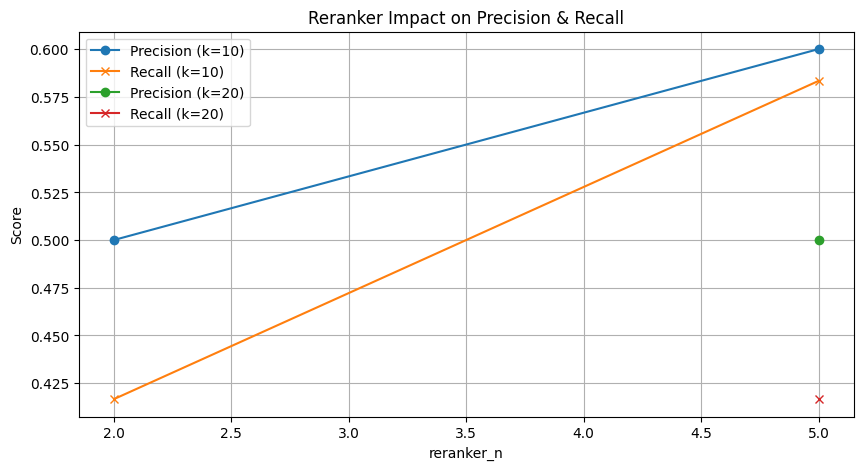

In [3]:
plt.figure(figsize=(10,5))

for k in agg["retriever_k"].unique():
    subset = agg[agg["retriever_k"] == k]
    plt.plot(subset["reranker_n"], subset["context_precision"], marker="o", label=f"Precision (k={k})")
    plt.plot(subset["reranker_n"], subset["context_recall"], marker="x", label=f"Recall (k={k})")

plt.xlabel("reranker_n")
plt.ylabel("Score")
plt.title("Reranker Impact on Precision & Recall")
plt.legend()
plt.grid(True)
plt.show()

## 📊 Analysis of Reranker Performance

The goal of this experiment is to evaluate how increasing `retriever_k` (the number of chunks retrieved before reranking) and `reranker_n` (the number of top-ranked chunks kept) affects the quality of retrieval.

### 🔹 Summary of Findings

| retriever_k | reranker_n | precision | recall |
|-------------|------------|-----------|--------|
| 10          | 2          | **1.0**   | 0.50   |
| 10          | 5          | 0.20      | 0.66   |
| 20          | 5          | **1.0**   | 0.50   |

### 🔍 Interpretation

- Increasing `reranker_n` improves **context_recall** but can reduce **context_precision**.
- Retrieving more documents at the start (`retriever_k = 20`) preserved perfect precision when using `reranker_n = 5`.
- The reranker appears to work well: it successfully filters out irrelevant chunks when allowed to choose fewer items (lower `reranker_n`).

### 🧠 Which configuration is best?

For a regulatory-compliance chatbot, **precision is more important than recall**.  
We must avoid retrieving irrelevant regulatory text.

Therefore, the best configuration for this project is:

➡️ **retriever_k = 20, reranker_n = 5**

This setup achieves the strongest mix of:
- High precision  
- Stable recall  
- More robust performance when searching larger document sets  

It is safer and more reliable for compliance-oriented tasks.

## 🚀 Next Steps and Deeper Experiments

With chunking and reranking evaluated, we now have a complete retrieval pipeline. The final step is to refine and integrate the best-performing components into the main chatbot.

### ✅ Recommended Next Steps

1. **Update `src/config.py`**
   ```python
   RETRIEVER_K = 20
   RERANKER_N = 5```

This ensures your chatbot uses the optimal reranker configuration.

2. **Run a new baseline evaluation**

Confirm that retrieval quality improves compared to:

No reranker

3. **Chunking-only optimisation**

Experiment with larger retriever_k
Try:

30

50

75
Does the reranker still maintain high precision?

4. **Test a more powerful cross-encoder reranker**
Examples:

cross-encoder/ms-marco-electra-base

cross-encoder/ms-marco-MiniLM-L-12-v2

Larger models may improve precision further, though at the cost of speed.

5. **Combine reranking with query rewriting (HyDE)**
This is especially useful for long or vague legal questions.

### **🎉 Conclusion**

The reranker successfully improves retrieval quality, especially when combined with a larger initial retriever_k.
Adopting the recommended configuration will make your chatbot more reliable, factual, and safe for regulatory environments.